# Draft Visualizations

This notebook converts the exploratory findings into draft visuals for the Netflix and Disney+ comparison.

The charts use raw counts only when catalog size itself is the subject. All direct comparisons of catalog composition use within-platform percentages because Netflix contains substantially more titles than Disney+.

Country shares use fractional title credit and exclude `Unknown` country values. The country field represents production origin rather than every location where a title was available to stream.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [ ]:
PROCESSED_DATA_DIR = Path("../data/processed")
OUTPUT_TABLE_DIR = Path("../outputs/tables")
FIGURE_DIR = Path("../outputs/figures/notebook_05_draft_v1")

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
titles = pd.read_csv(
    PROCESSED_DATA_DIR / "streaming_titles_clean.csv",
    parse_dates=["date_added"]
)

countries = pd.read_csv(
    PROCESSED_DATA_DIR / "streaming_titles_by_country.csv",
    parse_dates=["date_added"]
)

In [4]:
sns.set_theme(
    style="whitegrid",
    context="talk"
)

PLATFORM_COLORS = {
    "Netflix": "#E50914",
    "Disney+": "#1939B7"
}

TYPE_COLORS = {
    "Movie": "#4C78A8",
    "TV Show": "#F2B134"
}

In [ ]:
def save_figure(fig, filename, overwrite=False):
    output_path = FIGURE_DIR / filename

    if output_path.exists() and not overwrite:
        raise FileExistsError(
            f"{output_path} already exists. Set overwrite=True to overwrite the file."
        )
    
    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    print(f"Saved: {output_path}")

Saved: ..\outputs\figures\01_catalog_size.png


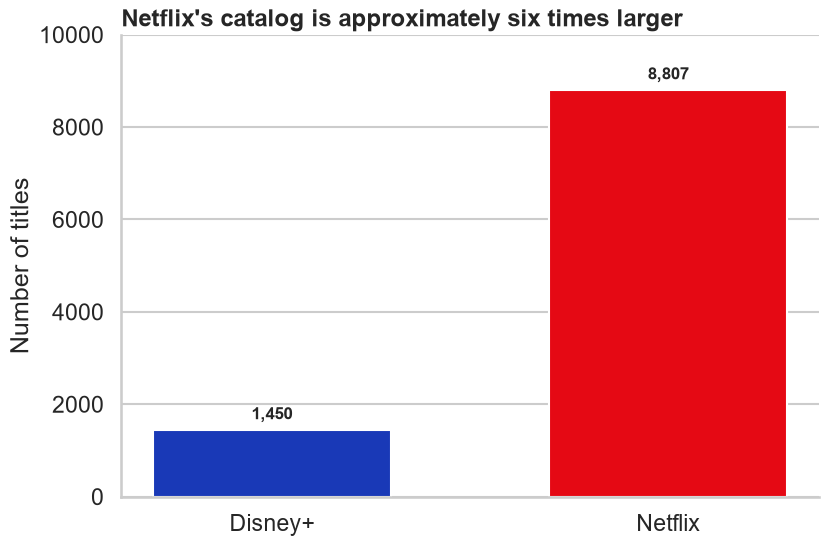

In [6]:
catalog_size = (
    titles
    .groupby("platform")
    .agg(total_titles=("content_id", "nunique"))
    .reindex(["Disney+", "Netflix"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    catalog_size["platform"],
    catalog_size["total_titles"],
    color=[
        PLATFORM_COLORS[platform]
        for platform in catalog_size["platform"]
    ],
    width=0.6
)

ax.bar_label(
    bars,
    labels=[
        f"{value:,}"
        for value in catalog_size["total_titles"]
    ],
    padding=5,
    fontsize=12,
    fontweight="bold"
)

ax.set_title(
    "Netflix's catalog is approximately six times larger",
    loc="left",
    fontsize=17,
    fontweight="bold"
)

ax.set_ylabel("Number of titles")
ax.set_xlabel("")
ax.set_ylim(0, 10000)
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)

save_figure(fig, "01_catalog_size.png")
plt.show()

In [7]:
content_type_summary = (
    titles
    .groupby(["platform", "type"])
    .agg(title_count=("content_id", "nunique"))
    .reset_index()
)

content_type_summary["platform_percentage"] = (
    content_type_summary["title_count"]
    / content_type_summary.groupby(
        "platform"
    )["title_count"].transform("sum")
    * 100
)

content_type_plot = (
    content_type_summary
    .pivot(
        index="platform",
        columns="type",
        values="platform_percentage"
    )
    .reindex(["Disney+", "Netflix"])
    [["Movie", "TV Show"]]
)

Saved: ..\outputs\figures\02_content_type_balance.png


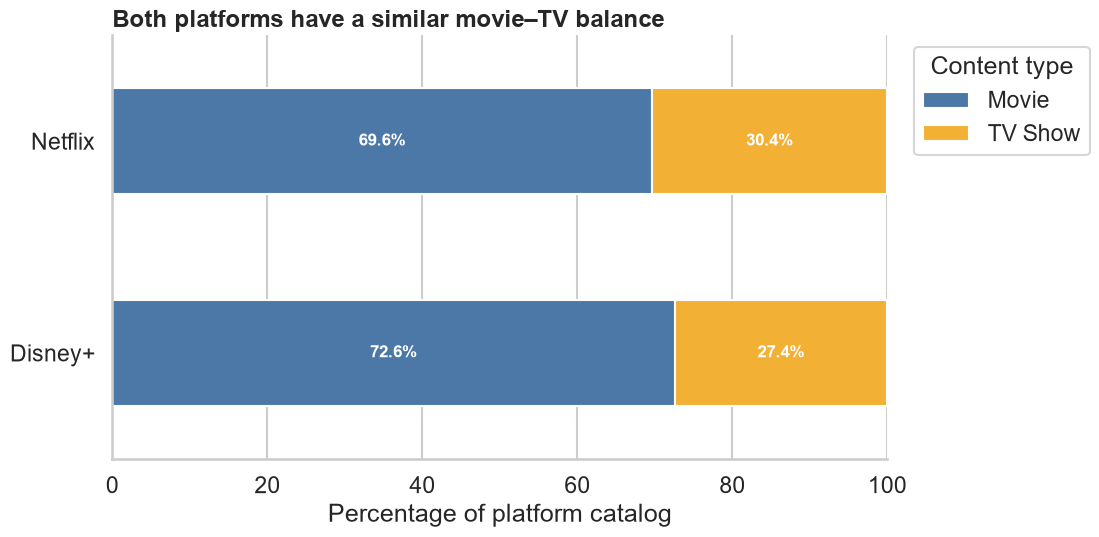

In [8]:
fig, ax = plt.subplots(figsize=(10, 5.5))

content_type_plot.plot(
    kind="barh",
    stacked=True,
    color=[
        TYPE_COLORS["Movie"],
        TYPE_COLORS["TV Show"]
    ],
    ax=ax
)

for row_number, platform in enumerate(content_type_plot.index):
    cumulative_position = 0

    for content_type in content_type_plot.columns:
        value = content_type_plot.loc[
            platform,
            content_type
        ]

        ax.text(
            cumulative_position + value / 2,
            row_number,
            f"{value:.1f}%",
            ha="center",
            va="center",
            color="white",
            fontweight="bold",
            fontsize=12
        )

        cumulative_position += value

ax.set_title(
    "Both platforms have a similar movie–TV balance",
    loc="left",
    fontsize=17,
    fontweight="bold"
)

ax.set_xlabel("Percentage of platform catalog")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.legend(
    title="Content type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

sns.despine(ax=ax)

save_figure(fig, "02_content_type_balance.png")
plt.show()

In [9]:
titles["release_decade"] = (
    (titles["release_year"] // 10) * 10
).astype(int)

release_decade_summary = (
    titles
    .groupby(["platform", "release_decade"])
    .agg(title_count=("content_id", "nunique"))
    .reset_index()
)

release_decade_summary["platform_percentage"] = (
    release_decade_summary["title_count"]
    / release_decade_summary.groupby(
        "platform"
    )["title_count"].transform("sum")
    * 100
)

Saved: ..\outputs\figures\03_release_decade_profile.png


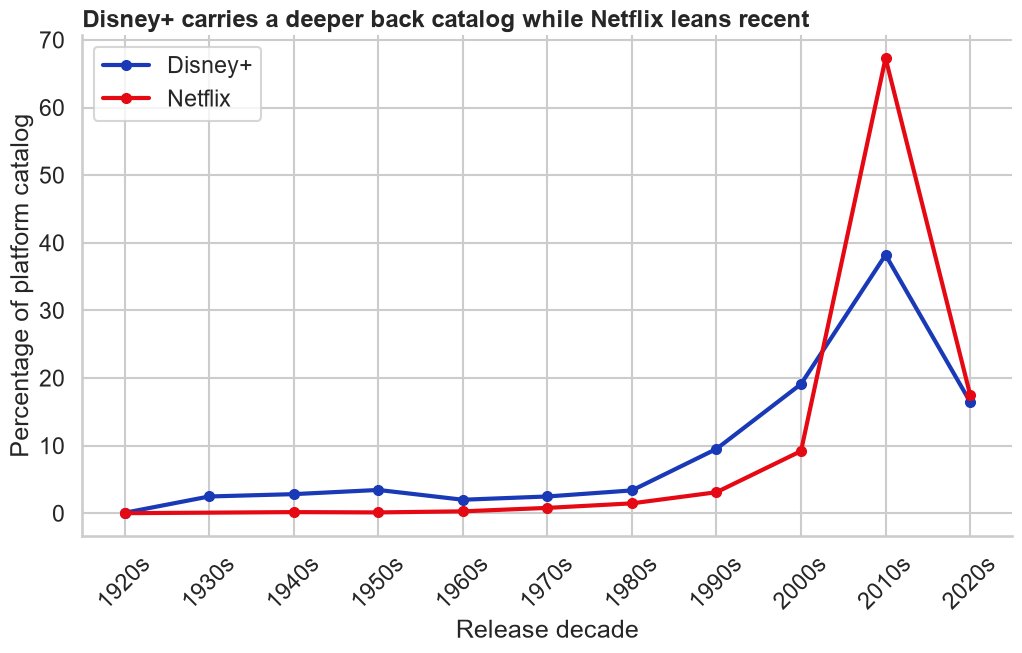

In [10]:
fig, ax = plt.subplots(figsize=(12, 6.5))

for platform in ["Disney+", "Netflix"]:
    platform_data = release_decade_summary[
        release_decade_summary["platform"] == platform
    ].sort_values("release_decade")

    ax.plot(
        platform_data["release_decade"],
        platform_data["platform_percentage"],
        marker="o",
        linewidth=3,
        markersize=7,
        label=platform,
        color=PLATFORM_COLORS[platform]
    )

ax.set_title(
    "Disney+ carries a deeper back catalog while Netflix leans recent",
    loc="left",
    fontsize=17,
    fontweight="bold"
)

ax.set_xlabel("Release decade")
ax.set_ylabel("Percentage of platform catalog")
ax.set_xticks(
    sorted(release_decade_summary["release_decade"].unique())
)
ax.set_xticklabels(
    [
        f"{decade}s"
        for decade in sorted(
            release_decade_summary["release_decade"].unique()
        )
    ],
    rotation=45
)

ax.legend(title="")
sns.despine(ax=ax)

save_figure(fig, "03_release_decade_profile.png")
plt.show()

In [11]:
known_countries = countries[
    countries["country"] != "Unknown"
].copy()

country_summary = (
    known_countries
    .groupby(["platform", "country"])
    .agg(
        fractional_titles=("fractional_credit", "sum")
    )
    .reset_index()
)

country_summary["known_platform_total"] = (
    country_summary
    .groupby("platform")["fractional_titles"]
    .transform("sum")
)

country_summary["country_share_percentage"] = (
    country_summary["fractional_titles"]
    / country_summary["known_platform_total"]
    * 100
)

In [12]:
us_share = (
    country_summary[
        country_summary["country"] == "United States"
    ]
    .set_index("platform")["country_share_percentage"]
)

top_five_share = (
    country_summary
    .sort_values(
        ["platform", "country_share_percentage"],
        ascending=[True, False]
    )
    .groupby("platform")
    .head(5)
    .groupby("platform")["country_share_percentage"]
    .sum()
)

In [13]:
concentration_plot = pd.DataFrame({
    "measure": [
        "United States share",
        "Top five countries"
    ],
    "Disney+": [
        us_share["Disney+"],
        top_five_share["Disney+"]
    ],
    "Netflix": [
        us_share["Netflix"],
        top_five_share["Netflix"]
    ]
})

concentration_long = concentration_plot.melt(
    id_vars="measure",
    var_name="platform",
    value_name="percentage"
)

Saved: ..\outputs\figures\04_geographic_concentration.png


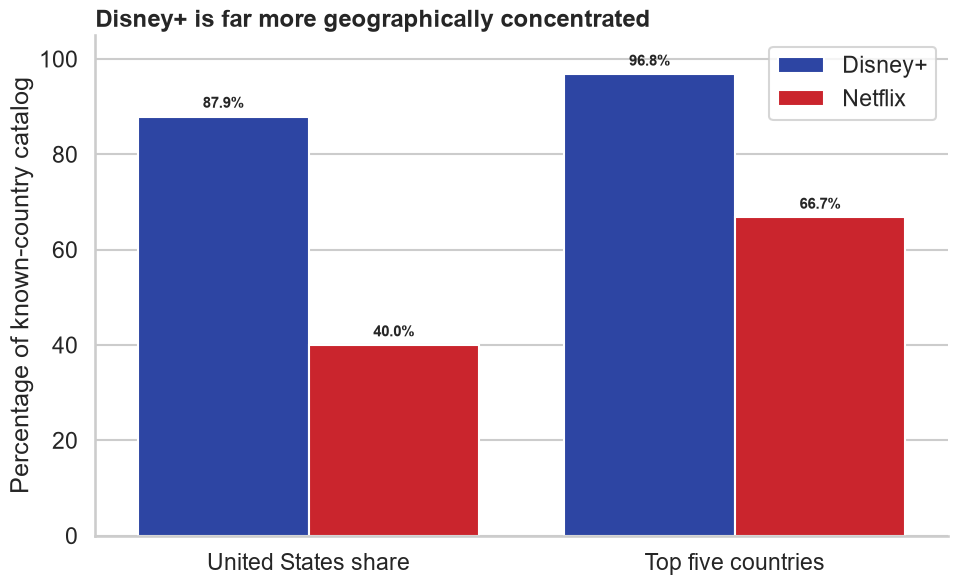

In [14]:
fig, ax = plt.subplots(figsize=(11, 6.5))

sns.barplot(
    data=concentration_long,
    x="measure",
    y="percentage",
    hue="platform",
    palette=PLATFORM_COLORS,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=4,
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Disney+ is far more geographically concentrated",
    loc="left",
    fontsize=17,
    fontweight="bold"
)

ax.set_xlabel("")
ax.set_ylabel("Percentage of known-country catalog")
ax.set_ylim(0, 105)
ax.legend(title="")
sns.despine(ax=ax)

save_figure(fig, "04_geographic_concentration.png")
plt.show()

In [15]:
country_comparison = (
    country_summary
    .pivot(
        index="country",
        columns="platform",
        values="country_share_percentage"
    )
    .fillna(0)
    .reset_index()
)

country_comparison["representation_gap"] = (
    country_comparison["Netflix"]
    - country_comparison["Disney+"]
)

netflix_country_totals = (
    country_summary[
        country_summary["platform"] == "Netflix"
    ][["country", "fractional_titles"]]
    .rename(
        columns={
            "fractional_titles":
            "netflix_fractional_titles"
        }
    )
)

country_comparison = country_comparison.merge(
    netflix_country_totals,
    on="country",
    how="left"
)

country_comparison["netflix_fractional_titles"] = (
    country_comparison["netflix_fractional_titles"]
    .fillna(0)
)

country_gap_plot = (
    country_comparison[
        country_comparison["netflix_fractional_titles"] >= 20
    ]
    .sort_values(
        "representation_gap",
        ascending=False
    )
    .head(8)
    .sort_values("representation_gap")
)

country_gap_long = country_gap_plot.melt(
    id_vars="country",
    value_vars=["Disney+", "Netflix"],
    var_name="platform",
    value_name="catalog_share"
)

Saved: ..\outputs\figures\05_country_representation_gaps.png


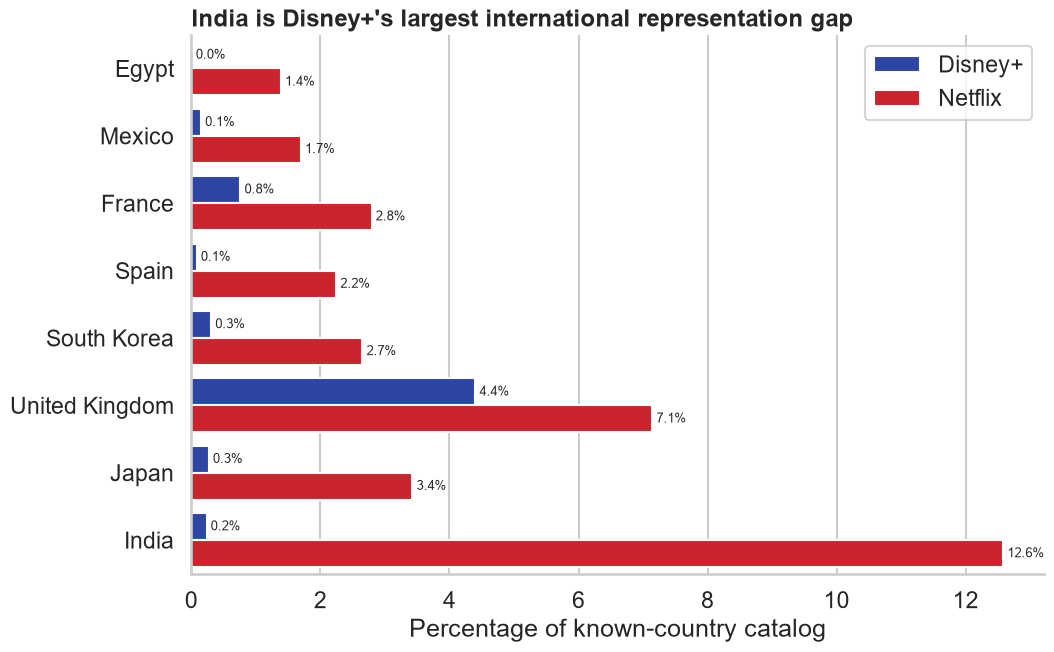

In [16]:
fig, ax = plt.subplots(figsize=(11, 7))

sns.barplot(
    data=country_gap_long,
    y="country",
    x="catalog_share",
    hue="platform",
    palette=PLATFORM_COLORS,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

ax.set_title(
    "India is Disney+'s largest international representation gap",
    loc="left",
    fontsize=17,
    fontweight="bold"
)

ax.set_xlabel("Percentage of known-country catalog")
ax.set_ylabel("")
ax.legend(title="")
sns.despine(ax=ax)

save_figure(fig, "05_country_representation_gaps.png")
plt.show()

## Exploratory Findings

### Catalog size and content type

Netflix contains 8,807 titles compared with 1,450 on Disney+, making the Netflix catalog approximately 6.1 times larger. Despite this difference, the platforms have a similar content-type balance: movies represent 69.62% of Netflix and 72.55% of Disney+, while TV shows represent 30.38% and 27.45%, respectively.

### Release-period differences

Disney+ has a median release year of 2011, compared with 2017 for Netflix. Disney+ contains a noticeably larger share of titles from before 2010, while 84.84% of Netflix titles were released during the 2010s or 2020s. This indicates that Disney+ maintains a deeper historical catalog, while Netflix is more concentrated in recent content.

### International representation

Netflix represents 122 known production countries, compared with 47 for Disney+. The United States accounts for 87.93% of Disney+'s known-country fractional catalog but only 39.98% of Netflix's.

The five leading production countries account for 96.77% of Disney+'s known-country catalog and 66.74% of Netflix's. Therefore, Disney+'s catalog is considerably more geographically concentrated.

### Representation differences

India produces the largest representation difference between the platforms, accounting for 12.58% of Netflix's known-country catalog but only 0.24% of Disney+'s. Additional differences appear in Japan, the United Kingdom, South Korea, Spain, France, Mexico, Egypt, Turkey, and Nigeria.

These results identify differences in catalog composition. They do not demonstrate audience demand, title popularity, licensing feasibility, profitability, or content quality.

### Genre limitation

Only two genre labels are shared exactly between the two platforms: `Docuseries` and `Movies`. Because the services use different classification systems, comparing raw genre labels would be misleading. Genre should either be standardized into carefully defined broader groups or treated as a secondary analysis.

## Primary Story Decision

The primary story of this project is geographic catalog concentration.

Disney+ represents fewer production countries than Netflix and assigns a substantially larger percentage of its known-country catalog to United States content. This geographic difference is stronger and more directly measurable than the initial differences in content type.

The final presentation should therefore lead with geographic representation and use the following evidence:

1. Netflix is approximately 6.1 times larger than Disney+.
2. The platforms have a similar movie-to-TV-show balance.
3. Netflix represents 122 known production countries, compared with 47 for Disney+.
4. United States content represents 87.93% of Disney+'s known-country catalog, compared with 39.98% of Netflix's.
5. Disney+'s top five production countries represent 96.77% of its known-country catalog, compared with 66.74% for Netflix.
6. India, Japan, the United Kingdom, South Korea, Spain, France, and Mexico show substantial representation differences.

The analysis supports further investigation into international content expansion. It does not establish audience demand, profitability, licensing feasibility, or the expected performance of future content.

## Supporting Role of Genre

Genre analysis will serve as supporting evidence rather than replace the primary geographic story.

The purpose of genre standardization is to determine whether Disney+'s geographic concentration is accompanied by a narrower or meaningfully different content mix. Because the two platforms use different genre taxonomies, all mappings must be documented and validated before drawing comparisons.

Genre findings will be included in the final presentation only if they:

1. Produce comparable coverage across both platforms.
2. Reveal a clear and meaningful difference.
3. Strengthen the geographic recommendation.
4. Can be explained without overwhelming the audience with taxonomy details.
5. Remain stable under reasonable alternative mapping decisions.

If the genre results are ambiguous or highly dependent on subjective mappings, they will be reported as exploratory findings rather than used as primary evidence.